In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("loan_data.csv")
print(df.head())

   person_age person_gender person_education  person_income  person_emp_exp  \
0        22.0        female           Master        71948.0               0   
1        21.0        female      High School        12282.0               0   
2        25.0        female      High School        12438.0               3   
3        23.0        female         Bachelor        79753.0               0   
4        24.0          male           Master        66135.0               1   

  person_home_ownership  loan_amnt loan_intent  loan_int_rate  \
0                  RENT    35000.0    PERSONAL          16.02   
1                   OWN     1000.0   EDUCATION          11.14   
2              MORTGAGE     5500.0     MEDICAL          12.87   
3                  RENT    35000.0     MEDICAL          15.23   
4                  RENT    35000.0     MEDICAL          14.27   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0                 0.49                         3.0           561  

In [3]:
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
print(df.describe())

Rows and columns: (45000, 14)

Column names:
['person_age', 'person_gender', 'person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'loan_status']

Data types:
person_age                        float64
person_gender                         str
person_education                      str
person_income                     float64
person_emp_exp                      int64
person_home_ownership                 str
loan_amnt                         float64
loan_intent                           str
loan_int_rate                     float64
loan_percent_income               float64
cb_person_cred_hist_length        float64
credit_score                        int64
previous_loan_defaults_on_file        str
loan_status                         int64
dtype: object
Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 45000

In [4]:
#now numerical
numerical_columns = [
    "person_age",
    "person_income",
    "person_emp_exp",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "credit_score"
]

print(df[numerical_columns].describe())

         person_age  person_income  person_emp_exp     loan_amnt  \
count  45000.000000   4.500000e+04    45000.000000  45000.000000   
mean      27.764178   8.031905e+04        5.410333   9583.157556   
std        6.045108   8.042250e+04        6.063532   6314.886691   
min       20.000000   8.000000e+03        0.000000    500.000000   
25%       24.000000   4.720400e+04        1.000000   5000.000000   
50%       26.000000   6.704800e+04        4.000000   8000.000000   
75%       30.000000   9.578925e+04        8.000000  12237.250000   
max      144.000000   7.200766e+06      125.000000  35000.000000   

       loan_int_rate  loan_percent_income  cb_person_cred_hist_length  \
count   45000.000000         45000.000000                45000.000000   
mean       11.006606             0.139725                    5.867489   
std         2.978808             0.087212                    3.879702   
min         5.420000             0.000000                    2.000000   
25%         8.590000  

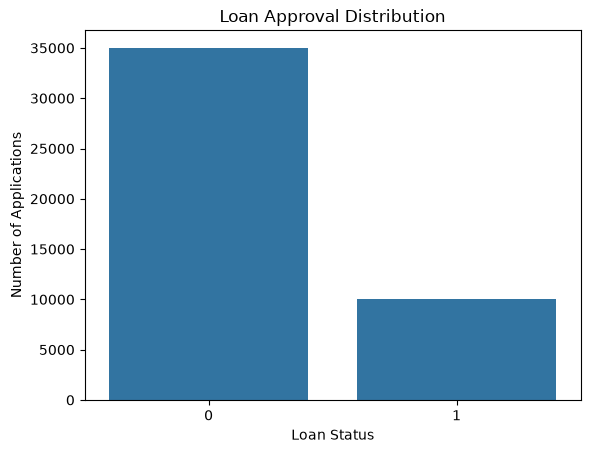

In [5]:
#visualizing target
sns.countplot(data=df, x="loan_status")

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.show()

In [6]:
#separate features and targets
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   person_age person_gender person_education  person_income  person_emp_exp  \
0        22.0        female           Master        71948.0               0   
1        21.0        female      High School        12282.0               0   
2        25.0        female      High School        12438.0               3   
3        23.0        female         Bachelor        79753.0               0   
4        24.0          male           Master        66135.0               1   

  person_home_ownership  loan_amnt loan_intent  loan_int_rate  \
0                  RENT    35000.0    PERSONAL          16.02   
1                   OWN     1000.0   EDUCATION          11.14   
2              MORTGAGE     5500.0     MEDICAL          12.87   
3                  RENT    35000.0     MEDICAL          15.23   
4                  RENT    35000.0     MEDICAL          14.27   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0                 0.49                         3.0      

In [7]:
#check target distribution
print("Loan Status Counts:")
print(y.value_counts())

print("\nLoan Status Percentages:")
print(y.value_counts(normalize=True) * 100)

Loan Status Counts:
loan_status
0    35000
1    10000
Name: count, dtype: int64

Loan Status Percentages:
loan_status
0    77.777778
1    22.222222
Name: proportion, dtype: float64


In [8]:
#cat and num columns
categorical_features = [
    "person_gender",
    "person_education",
    "person_home_ownership",
    "loan_intent",
    "previous_loan_defaults_on_file"
]

numerical_features = [
    "person_age",
    "person_income",
    "person_emp_exp",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "credit_score"
]

In [9]:
#train test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=51,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (36000, 13)
Testing data: (9000, 13)


In [10]:
#pipeline
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

In [11]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [12]:
#rf model
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]
)

In [13]:
#train
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [14]:
y_pred = rf_model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
[0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 0 0 0]


In [15]:
#approval probabilities
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Approval probabilities:")
print(y_prob[:20])

Approval probabilities:
[0.1  0.   0.   0.   0.   0.02 0.88 0.   0.   0.03 0.99 0.58 0.36 0.14
 0.   0.   0.   0.   0.   0.2 ]


In [16]:
#evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

Accuracy : 0.9288
Precision: 0.8957
Recall   : 0.769
F1-Score : 0.8275


In [17]:
#classfication report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.97      0.96      7000
           1       0.90      0.77      0.83      2000

    accuracy                           0.93      9000
   macro avg       0.92      0.87      0.89      9000
weighted avg       0.93      0.93      0.93      9000



Confusion Matrix:
[[6821  179]
 [ 462 1538]]


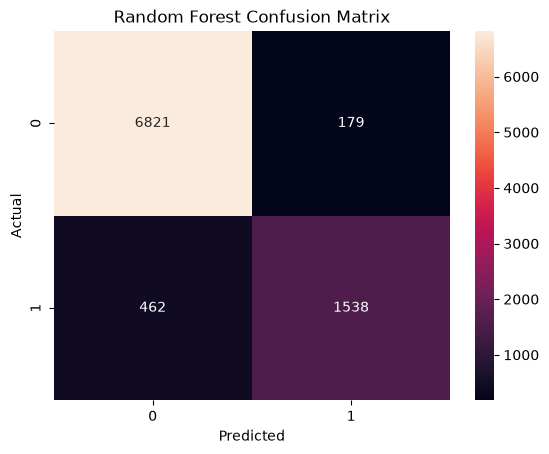

In [18]:
#confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d")

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [19]:
#for a new customer
new_applicant = pd.DataFrame({
    "person_age": [30],
    "person_gender": ["male"],
    "person_education": ["Bachelor"],
    "person_income": [55000],
    "person_emp_exp": [5],
    "person_home_ownership": ["RENT"],
    "loan_amnt": [20000],
    "loan_intent": ["PERSONAL"],
    "loan_int_rate": [11.0],
    "loan_percent_income": [20000 / 55000],
    "cb_person_cred_hist_length": [5],
    "credit_score": [640],
    "previous_loan_defaults_on_file": ["No"]
})

print(new_applicant)

   person_age person_gender person_education  person_income  person_emp_exp  \
0          30          male         Bachelor          55000               5   

  person_home_ownership  loan_amnt loan_intent  loan_int_rate  \
0                  RENT      20000    PERSONAL           11.0   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0             0.363636                           5           640   

  previous_loan_defaults_on_file  
0                             No  


In [20]:
prediction = rf_model.predict(new_applicant)

probability = rf_model.predict_proba(new_applicant)[:, 1]

print("Predicted Loan Status:", prediction[0])
print("Approval Probability:", probability[0])

Predicted Loan Status: 1
Approval Probability: 0.99


In [21]:
#result

print("Person Income:", 55000)
print("Loan Amount:", 20000)

print("\nPredicted Status:")

if prediction[0] == 1:
    print("Approved")
else:
    print("Not Approved")

print("Approval Probability:", round(probability[0] * 100, 2), "%")

Person Income: 55000
Loan Amount: 20000

Predicted Status:
Approved
Approval Probability: 99.0 %
